# How we used pen force to choose bigrams

We wanted to know whether the recognizer would benefit from treating some pairs of letters as one token. A frequency tokenizer asks **which pairs appear most often?** On this branch we asked **which pairs tend to be written while the pen stays in contact?**

We had pen sensor recordings and the word written in each recording. For each recording, we needed to locate the letters in time, inspect the force between them, and then see which patterns held across many words and writers.

In this notebook, **forced alignment** means using the known word to place letters in time. **Pen force** is the sensor reading we inspect at those estimated times.

Follow one recording first, then see what changed as we scaled up. The plots and tables are already saved. To rerun the code, use the TVA Python environment from the repository root with the processed dataset, A0 checkpoint, and saved experiment outputs.

## 1. Start with a word and a force trace

For this recording, the known word is **`Programm`**. The force trace shows when the pen presses down and when force drops. The transcript tells us the letters in order. We still need an estimate of **which part of the trace belongs to which letter**.

Expand the setup cell to change the training sample.

The model takes all 13 sensor channels. We keep the unmodified force channel to measure pen contact later.

In [1]:
import json
from itertools import groupby
from pathlib import Path
from tempfile import mkdtemp

import numpy as np
import torch
from IPython.display import Image, Markdown, display

from tva.alignment_analysis import analyze_alignment
from tva.alignment_runtime import load_config, load_model, token_text
from tva.boundary_export import BoundaryJSONLWriter, load_boundary_rows, make_boundary_rows
from tva.boundary_features import extract_boundary_features
from tva.ctc_alignment import ctc_viterbi_align
from tva.dataset import HRDataset, fn_collate
from tva.decoder_ctc import BestPath
from tva.tokenizers import get_tokenizer

sample_index = 18077
split = "train"
config_path = "configs/thesis/a0_char_wi_rh_unidirectional.yaml"
checkpoint_path = (
    "results/thesis/alignment_models/A0_char_wi_rh_unidirectional/0/checkpoints/best_cer.pth"
)
config = load_config(config_path)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = get_tokenizer("char")
tokenizer.load(Path(config.dir_tokenizer) / f"{config.idx_fold}.json")
model, checkpoint_epoch = load_model(config, tokenizer, checkpoint_path, device)

data_root = Path(config.dir_dataset)
annotation_path = data_root / f"{split}.json"
with annotation_path.open(encoding="utf-8") as file:
    sample_rate = float(json.load(file)["info"]["rate_sample_target"])
dataset = HRDataset(annotation_path, tokenizer, model.ratio_ds, config.idx_fold,
                    config.len_seq, aug=False, cache=False)
if not 0 <= sample_index < len(dataset):
    raise IndexError(f"Choose a training index between 0 and {len(dataset) - 1}.")
annotation = dataset.annos[sample_index]
signal, target = dataset[sample_index]
raw = np.loadtxt(data_root / annotation["filename"], delimiter=";", dtype=np.float32)
label = annotation["label"]
assert tokenizer.decode(target.tolist()) == label
if len(label) < 2:
    raise ValueError("Choose a label with at least two characters to export a boundary.")

print(f"Training sample {sample_index}  ·  fold {config.idx_fold}  ·  {label}")
print(f"Raw signal {len(raw)} samples × {raw.shape[1]} channels at {sample_rate:g} Hz")
print(f"A0 checkpoint epoch {checkpoint_epoch}  ·  {device}")

Training sample 18077  ·  fold 0  ·  Programm
Raw signal 303 samples × 13 channels at 100 Hz
A0 checkpoint epoch 275  ·  cuda


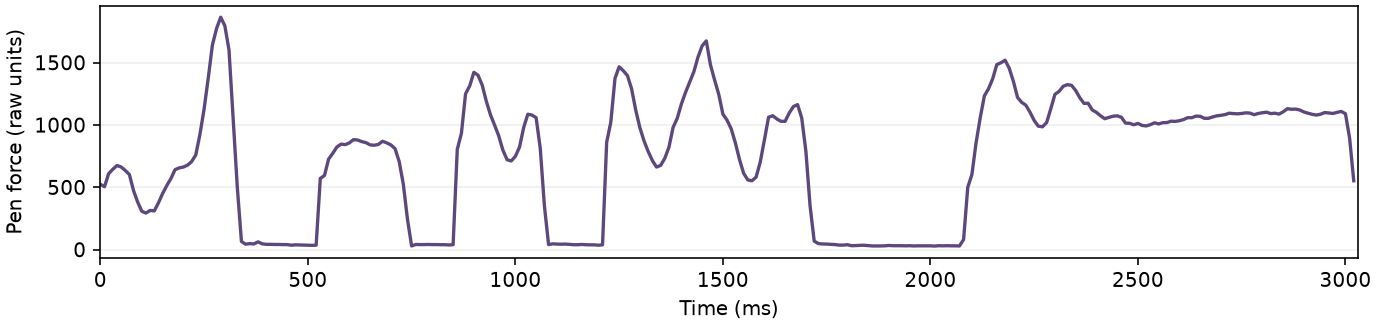

In [2]:
from io import BytesIO
from matplotlib import pyplot as plt

time_ms = np.arange(len(raw)) * 1_000 / sample_rate

def force_axis(height=2.25):
    fig, ax = plt.subplots(figsize=(9.5, height), layout="constrained")
    ax.plot(time_ms, raw[:, 12], color="#5d487d", linewidth=1.65, label="Raw force")
    ax.set(xlim=(0, len(raw) * 1_000 / sample_rate),
           xlabel="Time (ms)", ylabel="Pen force (raw units)")
    ax.grid(axis="y", alpha=0.20)
    return fig, ax

def display_plot(fig):
    png = BytesIO()
    fig.savefig(png, format="png", dpi=145)
    plt.close(fig)
    display(Image(data=png.getvalue(), width=880))

fig, ax = force_axis()
display_plot(fig)

## 2. Place the known letters on the timeline

The A0 character model reads the recording and outputs one probability distribution every **80 ms**. Reading off the model’s best guesses gives **`Progra`** for this example. That is what the model recognized on its own.

For alignment, we give CTC the known word **`Programm`**. It searches for the highest-probability frame-by-frame path that reads as that word after repeated frame labels are collapsed and blanks are removed. For instance, `m m ∅ m` collapses to `mm`. The two final letters need a blank between them so they stay distinct.

The search gives us approximate **emission times**. A CTC blank is a model symbol. We use the separate force trace to see what the pen was doing in that interval.

In [3]:
model_input, _, input_lengths, _ = fn_collate([(signal, target)])
frame_count = int(input_lengths[0]) // model.ratio_ds
with torch.inference_mode():
    probabilities = model(model_input.to(device))[0, :frame_count].cpu()

greedy = BestPath(tokenizer).decode(probabilities)
alignment = ctc_viterbi_align(probabilities, target, blank_id=0)
collapsed_ids = [idx for idx, _ in groupby(alignment.token_path) if idx != 0]
assert tokenizer.decode(collapsed_ids) == label

def display_path(ids):
    return " ".join(tokenizer.decode([idx]) if idx else "∅" for idx in ids)

print(f"Model probabilities {probabilities.shape[0]} frames × {probabilities.shape[1]} classes")
print(f"One model frame spans {1_000 * model.ratio_ds / sample_rate:g} ms")
print(f"Greedy reading       {greedy!r}")
print(f"Expanded target      {display_path(alignment.expanded_target)}")
print(f"Aligned frame path  {display_path(alignment.token_path)}")
print(f"Collapsed path       {tokenizer.decode(collapsed_ids)!r}")

Model probabilities 37 frames × 60 classes
One model frame spans 80 ms
Greedy reading       'Progra'
Expanded target      ∅ P ∅ r ∅ o ∅ g ∅ r ∅ a ∅ m ∅ m ∅
Aligned frame path  P ∅ ∅ ∅ ∅ ∅ ∅ r ∅ ∅ ∅ o ∅ ∅ ∅ ∅ g g ∅ r r ∅ ∅ ∅ ∅ ∅ ∅ a ∅ ∅ ∅ ∅ ∅ ∅ m ∅ m
Collapsed path       'Programm'


## 3. Measure the gaps and save the evidence

Overlay the letter estimates on the same force trace. **Orange bands** mark CTC gaps. **Green markers** show letters that agree with the model’s local guess. The two **red markers** at the end show where the known transcript requires letters the model didn’t choose.

For each gap we measure force in a **100 ms window centred on the gap** and across the **whole gap**. We also save 50 and 150 ms windows for inspection. The dashed line marks the low-force threshold, set at 10% of the recording’s 90th-percentile force. If CTC gives a zero-length gap, the whole-gap measurement uses a flagged 100 ms fallback.

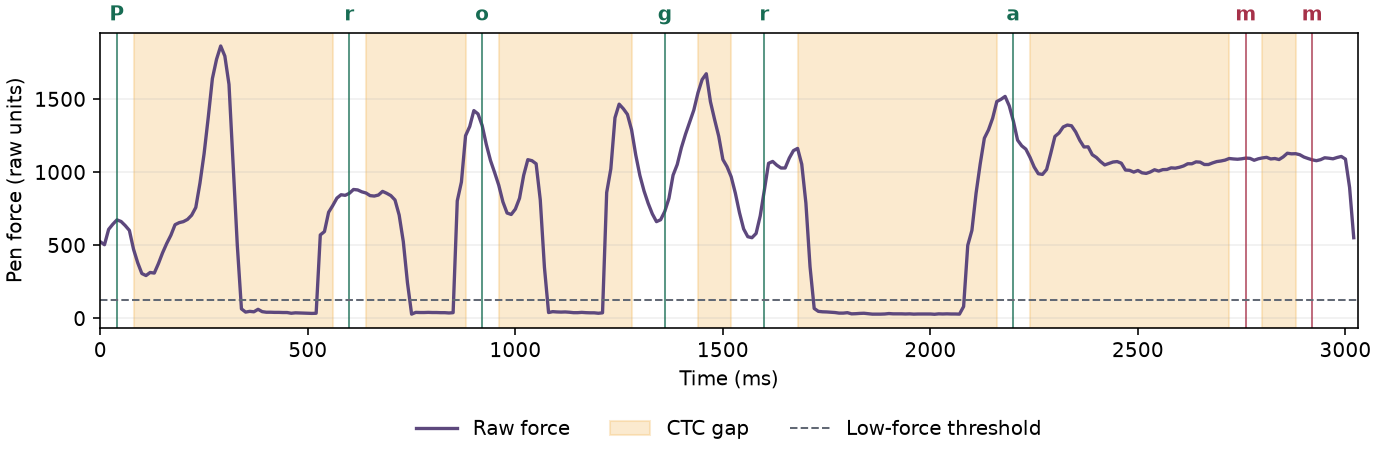

In [4]:
analysis = analyze_alignment(
    alignment=alignment, probabilities=probabilities,
    token_to_text=lambda idx: token_text(tokenizer, idx),
    downsampling_ratio=model.ratio_ds, num_model_input_samples=len(signal),
    num_raw_samples=len(raw), sample_rate_hz=sample_rate,
)
evidence = extract_boundary_features(
    raw_signal=raw, normalized_signal=signal.numpy(), alignment_analysis=analysis
)

fig, ax = force_axis(3.1)
to_ms = 1_000 / sample_rate
for index, gap in enumerate(analysis.boundaries):
    left = gap.input_start_sample * to_ms
    right = gap.input_end_sample * to_ms
    if gap.num_blank_frames:
        ax.axvspan(left, right, color="#f1b656", alpha=0.28,
                   label="CTC gap" if index == 0 else None, zorder=0)
    else:
        ax.axvline(left, color="#c97b16", alpha=0.5, linestyle=":")
for char in analysis.characters:
    time = char.anchor_input_sample * to_ms
    color = "#176c53" if char.agrees_with_greedy else "#a63149"
    ax.axvline(time, color=color, linewidth=1, alpha=0.70)
    ax.text(time, 1.025, char.text, color=color, ha="center", va="bottom",
            transform=ax.get_xaxis_transform(), fontweight="bold", clip_on=False)
ax.axhline(evidence.low_force_threshold_raw, color="#626975", linestyle="--",
           linewidth=1, label="Low-force threshold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3, frameon=False)
display_plot(fig)

In [5]:
rows = make_boundary_rows(
    config_path=config_path, checkpoint_path=checkpoint_path,
    checkpoint_epoch=checkpoint_epoch, split=split, fold=config.idx_fold,
    sample_index=sample_index, annotation=annotation, known_label=label,
    greedy_prediction=greedy, raw_num_samples=len(raw),
    model_input_num_samples=len(signal), alignment=alignment, analysis=analysis,
    features=evidence,
)
output_root = Path("results/thesis/alignment_debug/notebook_demo")
output_root.mkdir(parents=True, exist_ok=True)
output = Path(mkdtemp(prefix=f"{split}_{sample_index:05d}_", dir=output_root))
export_path = output / "boundaries.jsonl"
with BoundaryJSONLWriter(export_path) as writer:
    writer.write_sample(sample_index, rows)
saved_rows = load_boundary_rows(export_path)
assert saved_rows == rows and len(rows) == len(label) - 1

table = [
    "| Pair | CTC gap | Low force in 100 ms window | Low force across gap¹ | Passes alignment filter |",
    "| --- | ---: | ---: | ---: | --- |",
]
for row in saved_rows:
    window = row["windows_ms"]["100"]
    region = row["candidate_region"]
    usable = (row["both_anchors_agree_with_greedy"] and not row["overlaps_padding"]
              and not window["clipped_at_recording_edge"]
              and not region["clipped_at_recording_edge"])
    table.append(f"| `{row['pair']}` | {row['blank_duration_ms']:.0f} ms | "
                 f"{window['low_force_fraction']:.0%} | {region['low_force_fraction']:.0%} | "
                 f"{'Yes' if usable else 'No'} |")
display(Markdown("\n".join(table) + "\n\n¹ Uses the marked fallback if the CTC gap is empty."))
print(f"Saved {len(rows)} evidence rows to {export_path}")

| Pair | CTC gap | Low force in 100 ms window | Low force across gap¹ | Passes alignment filter |
| --- | ---: | ---: | ---: | --- |
| `Pr` | 480 ms | 30% | 40% | Yes |
| `ro` | 240 ms | 60% | 46% | Yes |
| `og` | 320 ms | 90% | 44% | Yes |
| `gr` | 80 ms | 0% | 0% | Yes |
| `ra` | 480 ms | 100% | 77% | Yes |
| `am` | 480 ms | 0% | 0% | No |
| `mm` | 80 ms | 0% | 0% | No |

¹ Uses the marked fallback if the CTC gap is empty.

Saved 7 evidence rows to results/thesis/alignment_debug/notebook_demo/train_18077_cf3afxvz/boundaries.jsonl


Three rows tell us why the export stores both force and alignment information.

- **`ro`** passes the alignment filter and has low force in **60%** of its middle window. The scorer records a drop there.
- **`gr`** passes the filter and stays above threshold in both measurements. This occurrence contributes contact evidence for `gr`.
- **`mm`** also stays above threshold. The model’s local guesses disagree with the placed letters, so the row is saved for inspection and excluded from scoring.

Open the exported JSONL to see the full record for each gap, including its frame-derived position, aligned probabilities and all force measurements.

## 4. Fix the early timing problem before scaling up

Our first aligner, **B0**, used a bidirectional LSTM. It could use later parts of the word when it emitted early letters. Many first gaps landed one frame into the recording, about **80 ms** from its start. That placed the force windows very early.

We trained **A0** with a unidirectional LSTM and reran the timing checks. For first gaps in words with more than two letters, the median offset from a rough equal-spacing reference moved from **−300 ms to −47 ms**. That was enough to choose A0 for the export. The reference was a timing sanity check. We did not have hand-labelled physical boundaries.

The full export ran on **19,907 training recordings**, saving **88,292 gap rows** like the seven above. **78,953** passed the filter. A row needs agreement at both anchors and usable force measurements inside the real recording.

## 5. Rank pairs using evidence from many writers

For each usable occurrence, we ask whether the force stayed above threshold in each measurement. A first gap or a long gap may behave differently from a middle or short one. The scorer adjusts for those differences, then averages within each writer before giving writers equal weight.

The score combines **75% from the corrected 100 ms measurement** and **25% from the corrected whole-gap measurement**. We required at least **100 usable occurrences across 30 writers**. Of the 422 pairs with usable observations, **176 were eligible** for ranking.

In [6]:
import csv

baseline = Path("results/thesis/forced_alignment_review/wi_rh_fold0_20261115_baseline")
with (baseline / "pair_continuity_scores.csv").open(newline="", encoding="utf-8") as file:
    ranking = {row["pair"]: row for row in csv.DictReader(file)}
gr = ranking["gr"]
local = float(gr["adjusted_local_contact_score"])
region = float(gr["adjusted_region_contact_score"])
score = float(gr["provisional_force_continuity_score"])
assert np.isclose(score, 0.75 * local + 0.25 * region)

print(f"gr ranked {gr['rank']} of 176 eligible pairs")
print(f"Support      {gr['occurrence_count']} usable occurrences from {gr['writer_count']} writers")
print(f"Score        0.75 × {local:.3f} + 0.25 × {region:.3f} ≈ {score:.3f}")

gr ranked 6 of 176 eligible pairs
Support      109 usable occurrences from 41 writers
Score        0.75 × 0.707 + 0.25 × 0.391 ≈ 0.628


## 6. Check what could change that ranking

- **Reproduce it.** We reran the original scorer and reproduced the saved pair ranking. That gave us a fixed version to test.
- **Remove a word or writer.** The leaders were broadly stable, but 42 of the 176 pairs lost eligibility after at least one word removal. For example, removing all `Programm` recordings left too little support for `gr`.
- **Inspect 100 traces.** Some drops were inside the wider CTC gap and outside the middle window. Some gaps contained several drops. We then tried detecting each whole drop first and assigning it only when the association with a gap was clear. Shifting the estimated gap one frame earlier or later (80 ms) changed the association in **50 of 100** cases.

Those checks explain why Bigram v0 uses the reproduced score and why the whole-drop assignment is still a diagnostic. The score gives a provisional ordering of pairs. A high rank alone cannot establish physical contact for any particular gap. [Method and audit details](docs/FORCED_ALIGNMENT.md)

## 7. Turn the ranking into a tokenizer

We kept all the characters as fallbacks. For one vocabulary, we added the top **100 force-ranked pairs**. For the control, we added the top **100 pairs by text frequency** from the **same 176 candidates**. The two lists shared 58 pairs.

Both tokenizers read left to right. If the next two letters form a known pair, they emit that pair. Otherwise they emit the next single character. Here is what that does to the word we started with.

In [7]:
vocab_dir = Path("results/thesis/forced_alignment_review/wi_rh_fold0_20261117_bigram_v0")
table = ["| Vocabulary | `Programm` split |", "| --- | --- |",
         "| Characters | `" + " · ".join("Programm") + "` |"]
for condition in ("force", "frequency"):
    bigram = get_tokenizer("bigram")
    bigram.load(vocab_dir / condition / "0.json")
    tokens = [bigram.idx_token[idx] for idx in bigram.encode("Programm")]
    assert "".join(tokens) == "Programm"
    table.append(f"| {condition.capitalize()} | `" + " · ".join(tokens) + "` |")
display(Markdown("\n".join(table)))

| Vocabulary | `Programm` split |
| --- | --- |
| Characters | `P · r · o · g · r · a · m · m` |
| Force | `Pr · o · gr · am · m` |
| Frequency | `P · ro · g · ra · mm` |

## 8. Test whether the new targets help recognition

We trained the two bigram recognizers, then compared their final checkpoints with the existing character checkpoint on the same **5,292 recordings from 11 held-out writers**. **CER** measures character edits. **WER** measures wrong words on this single-word dataset.

In [8]:
result_path = Path(
    "results/thesis/bigram/wi_rh_fold0_bigram_v0_pilot/seed_42/evaluation_20261119/summary.json"
)
results = json.loads(result_path.read_text(encoding="utf-8"))
table = ["| Target vocabulary | CER | WER |", "| --- | ---: | ---: |"]
for label, rates in results["rates"].items():
    table.append(f"| {label.capitalize()} | {rates['cer_percent']:.2f}% | "
                 f"{rates['wer_percent']:.2f}% |")
display(Markdown("\n".join(table)))

| Target vocabulary | CER | WER |
| --- | ---: | ---: |
| Character | 15.80% | 28.10% |
| Frequency | 16.74% | 25.42% |
| Force | 16.28% | 25.53% |

Force ranking lowered CER by **0.46 percentage points** compared with frequency ranking. The writer-based 95% interval was **−1.15 to +0.06 points**, which leaves that advantage uncertain. The character model had the lowest CER. Both bigram models got more whole words right. This was one seed and one fold, and the original A0 checkpoint had been selected using that fold’s validation scores.

The branch now gives us a way to go from **recorded force to a vocabulary we can test**. The strongest evidence so far is that the method runs end to end and that the two bigram rankings produce different targets. We still need stronger evidence for physical timing and for a recognition benefit from force ranking. [Tokenizer demo](bigram_v0_demo.ipynb) · [Recognition results and limits](docs/FORCED_ALIGNMENT.md#2026-11-19--onhw-bigram-v0-recognition-pilot-completed)